# 02 · Baseline на реальных данных: словари и правила без моделей

**Что такое baseline.** Это офлайн-конфигурация без нейросетей и без LLM. Все словари и пороги выучены только на train-группах каталога. Её нужно побить всем следующим экспериментам, и она остаётся запасным режимом решения.

**Источники кандидатов** (`attrx/lexicon.py`):

| Источник | Как работает |
|---|---|
| `brand` | бренд из справочника брендов train. Неоднозначные n-граммы отброшены по точности на train |
| `lexicon` | значение из справочника категории найдено в тексте: n-граммы токенов, нормализация единиц и ё. Плюс бонус, если рядом стоит название характеристики |
| `number` | число рядом с названием характеристики либо число с единицей, уникальной для категории |
| `flag` | булева характеристика упомянута без отрицания, значит «Да» |
| `kv` | пара «Ключ: значение» в описании, ключ совпадает с названием характеристики |

Кандидаты объединяет `attrx.merge`: согласные источники усиливают друг друга, противоречие снижает уверенность. У каждого значения есть evidence — поле и фрагмент текста.

Метрики и выборки описаны в [`docs/DATA_CONTRACT.md`](../docs/DATA_CONTRACT.md). Подбор только на val. На `test_core` считаем один раз за итерацию.

In [1]:
import json, os, time
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

from attrx.catalog import DataPaths, build, load, BRAND
from attrx.lexicon import Lexicon
from attrx import metrics as M

candidates = [os.environ.get("ATTRX_DATA_DIR"), "../data/real", str(Path.home() / "hackathon_data")]
DATA_DIR = next(Path(p) for p in candidates if p and (Path(p) / "cu_ws").exists())
P = DataPaths(DATA_DIR)
REPORTS, RESULTS, FIG = Path("../reports"), Path("../results"), Path("../reports/figures")
for d in (REPORTS, RESULTS, FIG):
    d.mkdir(parents=True, exist_ok=True)
pl.Config.set_tbl_rows(32); pl.Config.set_fmt_str_lengths(48); pl.Config.set_tbl_width_chars(170); pl.Config.set_tbl_cols(14)
if not (P.work / "cards.parquet").exists():
    print(build(P))
cards, gold, schema, ref, cats = (load(P, n) for n in ("cards", "gold", "schema", "reference", "categories"))
names = cats.select(pl.col("id").alias("category_id"), "name", "traffic_share")
SHOW = ["n_gold", "n_pred", "precision", "recall", "f1", "coverage", "recall_supported", "precision_accept", "auto_fill"]

## 1. Обучение справочников (только train)

In [2]:
train_titles = (cards.filter(pl.col("split") == "train").select("sku_id", "title")
                .join(gold.filter(pl.col("attribute") == BRAND).select("sku_id", pl.col("value").alias("brand")), on="sku_id"))
t = time.time(); lex_raw = Lexicon.fit(schema, ref); print("v0 без фильтра брендов:", lex_raw.stats, f"{time.time() - t:.1f} c")
t = time.time(); lex = Lexicon.fit(schema, ref, titles=train_titles); print("v1 с фильтром брендов:", lex.stats, f"{time.time() - t:.1f} c")

v0 без фильтра брендов: {'categories': 1093, 'slots': 21800, 'value_keys': 99501, 'brands': 5142, 'brands_dropped': 0} 1.1 c


v1 с фильтром брендов: {'categories': 1093, 'slots': 21800, 'value_keys': 99501, 'brands': 4735, 'brands_dropped': 407} 30.9 c


## 2. Метрики на `test_core`

`test_core` — это test-группы из топ-30 категорий по трафику, не больше 60 карточек на категорию и 20 на продавца. Доверительные интервалы считаются бутстрепом по карточкам.

In [3]:
core = M.eval_sample(cards, cats, "test")
sup_core = M.supported_flags(core, gold, schema)

def run(model, sample, sup):
    t = time.time(); preds = model.predict_frame(sample); ms = 1000 * (time.time() - t) / sample.height
    pairs = M.score_pairs(preds, gold, sample, schema, sup)
    return preds, pairs, ms

preds_raw, pairs_raw, ms_raw = run(lex_raw, core, sup_core)
preds, pairs, ms = run(lex, core, sup_core)
head = M.headline(pairs, cats) | {"ms_per_card": round(ms, 2), "cards": core.height}
lo, hi = M.bootstrap_ci(pairs, lambda p: M.traffic_weighted_f1(p, cats), n=200)
plo, phi = M.bootstrap_ci(pairs, lambda p: M.summarize(p)["precision"][0], n=200)
head |= {"traffic_weighted_f1_ci": [round(lo, 4), round(hi, 4)], "precision_ci": [round(plo, 4), round(phi, 4)]}
print(json.dumps(head, ensure_ascii=False, indent=1))

{
 "n_gold": 74702,
 "n_pred": 9882,
 "outside": 1235,
 "tp": 6482,
 "precision": 0.6559,
 "recall": 0.0868,
 "coverage": 0.1323,
 "precision_accept": 0.6693,
 "auto_fill": 0.0482,
 "n_supported": 11837,
 "recall_supported": 0.5444,
 "f1": 0.1533,
 "traffic_weighted_f1": 0.1551,
 "ece": 0.2064,
 "ms_per_card": 4.2,
 "cards": 1398,
 "traffic_weighted_f1_ci": [
  0.1499,
  0.1607
 ],
 "precision_ci": [
  0.6463,
  0.6642
 ]
}


In [4]:
bench = pl.concat([
    M.summarize(pairs_raw.filter(pl.col("attribute") == BRAND)).with_columns(pl.lit("v0: только бренд").alias("config")),
    M.summarize(pairs_raw).with_columns(pl.lit("v0: все источники").alias("config")),
    M.summarize(pairs.filter(pl.col("attribute") == BRAND)).with_columns(pl.lit("v1: только бренд").alias("config")),
    M.summarize(pairs).with_columns(pl.lit("v1: все источники").alias("config")),
], how="diagonal_relaxed")
bench.select("config", *SHOW)

config,n_gold,n_pred,precision,recall,f1,coverage,recall_supported,precision_accept,auto_fill
str,u32,u32,f64,f64,f64,f64,f64,f64,f64
"""v0: только бренд""",1398,1358,0.933726,0.90701,0.920174,0.971388,0.912887,0.951952,0.95279
"""v0: все источники""",74702,9920,0.65131,0.08649,0.152703,0.132794,0.542621,0.65812,0.048553
"""v1: только бренд""",1398,1320,0.976515,0.922031,0.948492,0.944206,0.928006,0.989256,0.932046
"""v1: все источники""",74702,9882,0.65594,0.086771,0.153268,0.132286,0.544395,0.669261,0.048165


## 3. Срезы

По типу характеристики, по источнику значения, по типу продавца (1P/3P) и по категориям с весом трафика.

In [5]:
M.summarize(pairs, "kind").select("kind", *SHOW)

kind,n_gold,n_pred,precision,recall,f1,coverage,recall_supported,precision_accept,auto_fill
str,u32,u32,f64,f64,f64,f64,f64,f64,f64
"""bool""",30964,1664,0.940505,0.050543,0.09593,0.05374,1.0,NaN,0.0
"""enum""",18505,3192,0.524749,0.090516,0.154399,0.172494,0.710997,0.559748,0.068738
"""num""",16504,2049,0.681796,0.084646,0.150596,0.124152,0.270334,0.444444,0.000545
"""text""",8729,2977,0.619751,0.211364,0.315223,0.341047,0.642186,0.730255,0.265437


In [6]:
M.summarize(pairs.filter(pl.col("pred").is_not_null()), "source").select("source", "n_pred", "precision", "precision_accept")

source,n_pred,precision,precision_accept
str,u32,f64,f64
"""lexicon""",4814,0.459078,0.484728
"""number""",2042,0.682174,0.0
"""flag""",1664,0.940505,NaN
"""brand""",1320,0.976515,0.989256
"""kv+lexicon""",20,0.95,0.95
"""kv""",15,0.133333,0.142857
"""kv+number""",7,0.571429,0.571429


In [7]:
M.summarize(pairs, "seller_type").select("seller_type", *SHOW)

seller_type,n_gold,n_pred,precision,recall,f1,coverage,recall_supported,precision_accept,auto_fill
str,u32,u32,f64,f64,f64,f64,f64,f64,f64
"""1P""",39509,5062,0.668906,0.085702,0.151937,0.128123,0.55994,0.6738,0.043762
"""3P""",35193,4820,0.642324,0.087972,0.15475,0.136959,0.528383,0.665062,0.053107


In [8]:
by_cat = (M.summarize(pairs, "category_id").join(names, on="category_id")
          .sort("traffic_share", descending=True)
          .select("name", "traffic_share", "n_gold", "precision", "recall", "f1", "recall_supported"))
by_cat.write_csv(REPORTS / "baseline_by_category.csv")
by_cat.head(15)

name,traffic_share,n_gold,precision,recall,f1,recall_supported
str,f64,u32,f64,f64,f64,f64
"""Смартфоны""",0.077452,5508,0.594156,0.066449,0.11953,0.544361
"""Стиральные машины""",0.051761,5416,0.69379,0.059823,0.110148,0.457627
"""Холодильники""",0.051405,3781,0.781671,0.076699,0.139692,0.495726
"""iPhone""",0.041058,3191,0.583004,0.092448,0.159589,0.56262
"""Телевизоры""",0.040522,6338,0.562563,0.088672,0.153196,0.549656
"""Ноутбуки""",0.030365,2613,0.715177,0.131649,0.222366,0.558442
"""Наушники""",0.029517,1647,0.674923,0.132362,0.22132,0.62
"""Пылесосы вертикальные""",0.023247,3383,0.663609,0.064144,0.116981,0.523457
"""Аэрогрили""",0.021868,5160,0.575203,0.054845,0.100142,0.531955


## 4. Пороги и калибровка

Уверенность источников пока задана вручную, поэтому калибровка — первое, что нужно проверить. Гейт контракта — `precision@accept ≥ 0.95` при авто-публикации.

ECE = 0.206

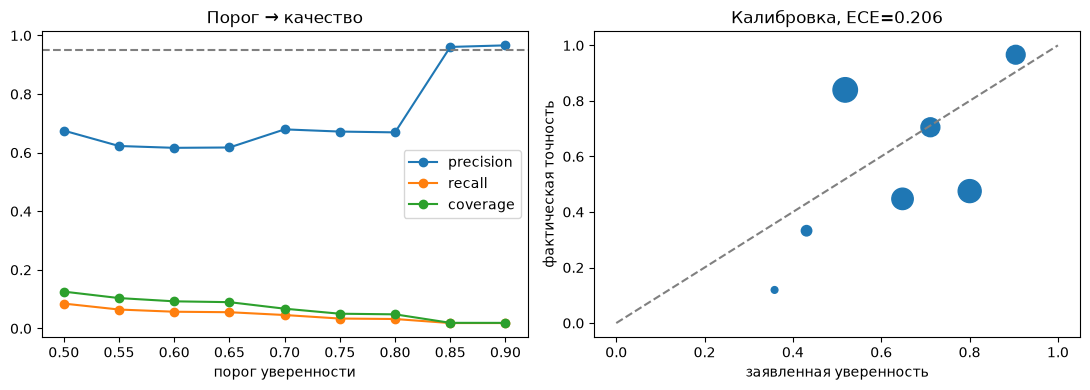

threshold,precision,recall,coverage,f1
f64,f64,f64,f64,f64
0.5,0.675327,0.084897,0.125713,0.150833
0.55,0.622724,0.064563,0.103679,0.116996
0.6,0.616486,0.057067,0.092568,0.104464
0.65,0.617634,0.05542,0.08973,0.101714
0.7,0.6795,0.045835,0.067455,0.085878
0.75,0.671991,0.033788,0.05028,0.06434
0.8,0.669261,0.032235,0.048165,0.061507
0.85,0.960867,0.018406,0.019156,0.036121
0.9,0.966245,0.018393,0.019036,0.036099


In [9]:
sweep = M.threshold_sweep(pairs, (0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9))
ece, table = M.calibration(pairs)
print(f"ECE = {ece:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(sweep["threshold"], sweep["precision"], "o-", label="precision")
ax[0].plot(sweep["threshold"], sweep["recall"], "o-", label="recall")
ax[0].plot(sweep["threshold"], sweep["coverage"], "o-", label="coverage")
ax[0].axhline(0.95, ls="--", c="gray"); ax[0].set_xlabel("порог уверенности"); ax[0].legend(); ax[0].set_title("Порог → качество")
ax[1].plot([0, 1], [0, 1], "--", c="gray")
ax[1].scatter(table["conf"], table["acc"], s=table["n"] / table["n"].max() * 300 + 10)
ax[1].set_xlabel("заявленная уверенность"); ax[1].set_ylabel("фактическая точность"); ax[1].set_title(f"Калибровка, ECE={ece:.3f}")
plt.tight_layout(); plt.savefig(FIG / "baseline_threshold_calibration.png"); plt.show()
sweep

## 5. Разбор ошибок

Ошибки разбиваем на три группы:
- **FP** — значение выдано, но неверное;
- **FN, подтверждаемые** — значение было в тексте, но мы его не нашли;
- **FN, неподтверждаемые** — значения в тексте нет; это потолок метода, а не ошибка.

In [10]:
wrong = pairs.filter(pl.col("pred").is_not_null() & pl.col("gold").is_not_null() & ~pl.col("correct"))
print("FP по источникам:", dict(wrong.group_by("source").len().sort("len", descending=True).iter_rows()))
print("FP по характеристикам (топ):")
wrong.group_by("attribute").len().sort("len", descending=True).head(12)

FP по источникам: {'lexicon': 2604, 'number': 649, 'flag': 99, 'brand': 31, 'kv': 13, 'kv+number': 3, 'kv+lexicon': 1}
FP по характеристикам (топ):


attribute,len
str,u32
"""Серия""",327
"""Модель""",170
"""Вес""",114
"""Потребляемая мощность""",91
"""Тип управления""",87
"""Функции""",84
"""Индикация""",81
"""Версия ОС""",58
"""Цвет""",57


In [11]:
(wrong.join(preds.select("sku_id", "attribute", "evidence_text"), on=["sku_id", "attribute"])
      .select("attribute", "gold", "gold_unit", "pred", "source", "confidence", "evidence_text")
      .sample(18, seed=1))

attribute,gold,gold_unit,pred,source,confidence,evidence_text
str,str,str,str,str,f64,str
"""Основная камера 1""","""48""","""МПикс""","""2""","""number""",0.7,"""2"""
"""Модель""","""15""",null,"""Xiaomi""","""lexicon""",0.7518,"""Xiaomi"""
"""Индикация""","""заданной температуры, неисправности, режима рабо…",null,"""заданной температуры, режима работы""","""lexicon""",0.8,"""заданной температуры, режима работы"""
"""Мощность фронтальных АС""","""2 x 8 Вт""",null,"""16 Вт""","""lexicon""",0.8,"""16 Вт"""
"""Наименование угольного фильтра""","""Ф-00""",null,"""угольный фильтр""","""lexicon""",0.65,"""угольный фильтр"""
"""Графический ускоритель""","""Apple A19 Pro GPU""",null,"""Apple""","""lexicon""",0.8,"""Apple"""
"""Потребляемая мощность""","""2050""","""Вт""","""1180""","""number""",0.55,"""1,18 кВт"""
"""Основная камера 2""","""10""","""МПикс""","""72""","""number""",0.7,"""72"""
"""Функция""","""инверторной технологии, автоматическое разморажи…",null,"""инверторной технологии""","""lexicon""",0.65,"""инверторной технологии"""


In [12]:
missed = pairs.filter(pl.col("supported") & ~pl.col("correct"))
print(f"пропущено подтверждаемых пар: {missed.height:,} из {pairs['supported'].sum():,}")
print(missed.group_by("kind").len().sort("len", descending=True))
missed.group_by("attribute").len().sort("len", descending=True).head(15)

пропущено подтверждаемых пар: 5,393 из 11,837
shape: (3, 2)
┌──────┬──────┐
│ kind ┆ len  │
│ ---  ┆ ---  │
│ str  ┆ u32  │
╞══════╪══════╡
│ num  ┆ 3687 │
│ text ┆ 1028 │
│ enum ┆ 678  │
└──────┴──────┘


attribute,len
str,u32
"""Серия""",530
"""Модель""",256
"""Ширина""",248
"""Высота""",239
"""Глубина""",213
"""Длина сетевого шнура""",108
"""Класс энергоэффективности""",105
"""Бренд""",100
"""Оперативная память (RAM)""",85


In [13]:
missed.join(core.select("sku_id", "title"), on="sku_id").select("attribute", "kind", "gold", "pred", "title").sample(15, seed=2)

attribute,kind,gold,pred,title
str,str,str,str,str
"""Фронтальная камера 1""","""num""","""50""",null,"""Восстановленный смартфон Motorola Edge 50 Pro 12…"
"""Бренд""","""text""","""Rapid""",null,"""Сплит-система Rapid RAM-18HJ/N1_23Y"""
"""Класс энергоэффективности""","""enum""","""A++""",null,"""Холодильник многодверный HAIER HB18FGWAAARU"""
"""Уровень шума при стирке""","""num""","""60""",null,"""Стиральная машина Hiberg i-DDQ6A - 1214 W"""
"""Количество режимов нагрева""","""num""","""1""",null,"""Электрочайник Kitfort КТ-6614"""
"""Диагональ""","""num""","""6.9""",null,"""Смартфон Xiaomi 17 Ultra 16/512Gb White Leica"""
"""Длина сетевого шнура""","""num""","""6.5""",null,"""Пылесос с контейнером для пыли Dyson CY26 Cineti…"
"""Подвесных корзин в комплекте""","""num""","""3""",null,"""Морозильная камера HAIER H3F-285WAA"""
"""Максимальный объем""","""num""","""1.7""",null,"""Электрочайник FuturoHome MTR KG-700S"""


## 6. Проверка утечки: случайное разбиение против группового

Строим такой же набор, но со случайным разбиением по `sku_id`. Если метрики заметно выше, групповое разбиение было необходимо: случайное завышает качество за счёт шаблонов продавцов.

In [14]:
W_RANDOM = P.root / "work_random"
if not (W_RANDOM / "cards.parquet").exists():
    print(build(P, split_by="random", out=W_RANDOM))
rc, rs, rr = (load(P, n, W_RANDOM) for n in ("cards", "schema", "reference"))
r_titles = (rc.filter(pl.col("split") == "train").select("sku_id", "title")
            .join(gold.filter(pl.col("attribute") == BRAND).select("sku_id", pl.col("value").alias("brand")), on="sku_id"))
lex_r = Lexicon.fit(rs, rr, titles=r_titles)
core_r = M.eval_sample(rc, cats, "test")
pairs_r = M.score_pairs(lex_r.predict_frame(core_r), gold, core_r, rs, M.supported_flags(core_r, gold, rs))
leak = pl.concat([
    M.summarize(pairs).with_columns(pl.lit("групповое (продавец/бренд)").alias("разбиение"),
                                     pl.lit(M.traffic_weighted_f1(pairs, cats)).alias("traffic_weighted_f1")),
    M.summarize(pairs_r).with_columns(pl.lit("случайное (sku)").alias("разбиение"),
                                       pl.lit(M.traffic_weighted_f1(pairs_r, cats)).alias("traffic_weighted_f1")),
])
leak.select("разбиение", "precision", "recall", "f1", "recall_supported", "traffic_weighted_f1")

{'offers': 546069, 'cards': 241355, 'gold': 5681479, 'reference': 654344, 'schema_rows': 22022, 'schema_categories': 1134}


разбиение,precision,recall,f1,recall_supported,traffic_weighted_f1
str,f64,f64,f64,f64,f64
"""групповое (продавец/бренд)""",0.65594,0.086771,0.153268,0.544395,0.155063
"""случайное (sku)""",0.684268,0.100481,0.175231,0.566721,0.176416


## 7. Полный test (быстрые конфигурации)

Весь test, не больше 200 карточек на продавца в категории, все категории.

In [15]:
full = M.eval_sample(cards, cats, "test", top_k=None, per_category=None, per_group=200)
t = time.time()
preds_full, pairs_full, ms_full = run(lex, full, M.supported_flags(full, gold, schema))
head_full = M.headline(pairs_full, cats) | {"ms_per_card": round(ms_full, 2), "cards": full.height}
print(f"{full.height:,} карточек, {time.time() - t:.0f} c")
print(json.dumps(head_full, ensure_ascii=False, indent=1))

27,107 карточек, 113 c
{
 "n_gold": 471574,
 "n_pred": 80082,
 "outside": 18764,
 "tp": 53595,
 "precision": 0.6693,
 "recall": 0.1137,
 "coverage": 0.1698,
 "precision_accept": 0.7225,
 "auto_fill": 0.0784,
 "n_supported": 102713,
 "recall_supported": 0.5163,
 "f1": 0.1943,
 "traffic_weighted_f1": 0.17,
 "ece": 0.1716,
 "ms_per_card": 2.46,
 "cards": 27107
}


## 8. Сохранение артефактов

In [16]:
report = {"config": "baseline (lexicon v1)", "data_snapshot": "2026-10-14", "split": "group md5(seller|1P brand) 70/10/20",
          "test_core": head, "test_full": head_full, "leakage_check": leak.select("разбиение", "precision", "recall", "f1").to_dicts(),
          "lexicon": lex.stats}
(REPORTS / "metrics_baseline.json").write_text(json.dumps(report, ensure_ascii=False, indent=1), encoding="utf-8")
preds.join(core.select("sku_id", "category_id"), on="sku_id").write_csv(RESULTS / "predictions_test_core_baseline.csv")
print("сохранено:", REPORTS / "metrics_baseline.json", RESULTS / "predictions_test_core_baseline.csv")

сохранено: ..\reports\metrics_baseline.json ..\results\predictions_test_core_baseline.csv
